In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import seaborn as sns
import numpy as np

In [3]:
# Load dataset
AFCD = pd.read_csv('Datasets/AFCD_Release3_NutrientProfiles_All_Solids&liquids_per_100g.csv')

AFCD.head()

,Public Food Key,Classification,Derivation,Food Name,"Energy with dietary fibre, equated (kJ)","Energy, without dietary fibre, equated (kJ)",Moisture (water) (g),Protein (g),Nitrogen (g),"Fat, total (g)",...,Leucine (mg),Lysine (mg),Methionine (mg),Phenylalanine (mg),Proline (mg),Serine (mg),Threonine (mg),Tyrosine (mg),Tryptophan (mg),Valine (mg)
0,F002258,31302,Borrowed,"Cardamom seed, dried, ground",1236,1012,8.3,10.8,1.72,6.7,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,155,NaN
1,F002963,31302,Borrowed,"Cinnamon, dried, ground",1004,579,10.6,4.0,0.64,1.2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,49,NaN
2,F002893,31302,Borrowed,"Chilli (chili), dried, ground",1224,950,10.8,12.3,2.00,14.3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64,NaN
3,F002970,31302,Borrowed,"Cloves, dried, ground",1389,1118,9.9,6.0,0.96,13.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30,NaN
4,F003190,31302,Borrowed,"Coriander seed, dried, ground",1344,1009,8.9,12.4,1.98,17.8,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,178,NaN


In [4]:
# Fix trailing spaces in Food Name
AFCD['Food Name'] = AFCD['Food Name'].str.strip()

# STEP 2 â€” Separate identifiers, target, and features
id_cols      = ['Public Food Key', 'Food Name', 'Classification', 'Derivation']
target       = 'Energy with dietary fibre, equated (kJ)'
leakage_cols = ['Energy, without dietary fibre, equated (kJ)']


feature_cols = [c for c in AFCD.columns
                if c not in id_cols + [target] + leakage_cols
                and AFCD[c].dtype in ['float64', 'int64']]

X = AFCD[feature_cols]
y = AFCD[target]

print(f"\nStep 2 complete â€” features: {X.shape[1]}, target rows: {len(y)}")



Step 2 complete â€” features: 266, target rows: 1588


In [5]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

In [6]:
# Drop missing values threshold
thresh_count = int(0.70 * len(X_train))

X_train = X_train.dropna(thresh=thresh_count, axis=1)
keep_cols = X_train.columns.tolist()   # save surviving columns

# Apply the same columns to test â€” never re-evaluate on test data
X_test = X_test[keep_cols]

print(f"\nStep 4 complete â€” columns before: {len(feature_cols)}, after: {len(keep_cols)}, dropped: {len(feature_cols) - len(keep_cols)}")



Step 4 complete â€” columns before: 266, after: 78, dropped: 188


In [7]:
for col in ['Protein (g)', 'Nitrogen (g)']:
    na_count = AFCD[col].isna().sum()
    print(f"{col}: {na_count} NA values ({na_count / len(AFCD) * 100:.1f}%)")

Protein (g): 0 NA values (0.0%)
Nitrogen (g): 0 NA values (0.0%)


In [8]:
check = AFCD[['Protein (g)', 'Nitrogen (g)']].dropna()
check['Protein_derived'] = check['Nitrogen (g)'] * 6.25
check['difference'] = (check['Protein (g)'] - check['Protein_derived']).abs()

exact_match  = (check['difference'] < 0.01).sum()
close_match  = (check['difference'] < 0.1).sum()
total        = len(check)

print(f"Rows with both values     : {total}")
print(f"Exact match  (diff < 0.01): {exact_match}  ({exact_match/total*100:.1f}%)")
print(f"Close match  (diff < 0.1) : {close_match}  ({close_match/total*100:.1f}%)")
print(f"\nMax difference  : {check['difference'].max():.4f} g")
print(f"Mean difference : {check['difference'].mean():.4f} g")
print(f"\nSample rows where difference >= 0.1:")
print(check[check['difference'] >= 0.1][['Protein (g)', 'Nitrogen (g)', 'Protein_derived', 'difference']].head(10))

Rows with both values     : 1588
Exact match  (diff < 0.01): 257  (16.2%)
Close match  (diff < 0.1) : 1260  (79.3%)

Max difference  : 37.4375 g
Mean difference : 0.2691 g

Sample rows where difference >= 0.1:
    Protein (g)  Nitrogen (g)  Protein_derived  difference
2          12.3          2.00          12.5000      0.2000
23          6.2          0.94           5.8750      0.3250
27          6.0          1.05           6.5625      0.5625
28         84.4         15.20          95.0000     10.6000
63         22.1          4.32          27.0000      4.9000
66          3.5          0.54           3.3750      0.1250
67         35.8          6.76          42.2500      6.4500
70         18.0          3.40          21.2500      3.2500
71         18.0          3.40          21.2500      3.2500
76          1.7          0.32           2.0000      0.3000


In [9]:
protein_cols = [col for col in X_test.columns if 'protein' in col.lower()]
carb_cols    = [col for col in X_test.columns if 'carbo' in col.lower()]
alcohol_cols = [col for col in X_test.columns if 'alcohol' in col.lower()]
fat_cols = [col for col in X_test.columns if 'fat' in col.lower()]

print("Protein:", protein_cols)
print("Fat:    ", fat_cols)
print("Carbs:  ", carb_cols)
print("Alcohol:", alcohol_cols)

Protein: ['Protein (g)']
Fat:     ['Fat, total (g)', 'Total saturated fatty acids, equated (%T)', 'Total monounsaturated fatty acids, equated (%T)', 'Total polyunsaturated fatty acids, equated (%T)', 'Total long chain omega 3 fatty acids, equated (%T)', 'Total trans fatty acids, imputed (%T)', 'Total saturated fatty acids, equated (g)', 'Total monounsaturated fatty acids, equated (g)', 'Total polyunsaturated fatty acids, equated (g)', 'Total long chain omega 3 fatty acids, equated (mg)', 'Total trans fatty acids, imputed (mg)']
Carbs:   ['Available carbohydrate, without sugar alcohols (g)', 'Available carbohydrate, with sugar alcohols (g)']
Alcohol: ['Alcohol (g)', 'Available carbohydrate, without sugar alcohols (g)', 'Available carbohydrate, with sugar alcohols (g)']


In [10]:
atwater_cols = [
    'Protein (g)',
    'Fat, total (g)',
    'Available carbohydrate, without sugar alcohols (g)',
    'Alcohol (g)',
]

for split_name, df in [('X_train', X_train), ('X_test', X_test)]:
    print(f"\nâ”€â”€ {split_name} ({len(df)} rows) â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€")
    print(f"{'Column':<52} {'Missing':>7}  {'%':>6}")
    print("-" * 68)
    for col in atwater_cols:
        if col in df.columns:
            n = df[col].isna().sum()
            pct = n / len(df) * 100
            print(f"{col:<52} {n:>7}  {pct:>5.1f}%")
        else:
            print(f"{col:<52}  *** NOT FOUND ***")


â”€â”€ X_train (1111 rows) â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
Column                                               Missing       %
--------------------------------------------------------------------
Protein (g)                                                0    0.0%
Fat, total (g)                                             0    0.0%
Available carbohydrate, without sugar alcohols (g)         0    0.0%
Alcohol (g)                                                0    0.0%

â”€â”€ X_test (477 rows) â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
Column                                               Missing       %
--------------------------------------------------------------------
Protein (g)                                                0    0.0%
Fat, total (g)                                             0    0.0%
Available carbohydrate, without sugar alcohols (g)         0    0.0%
Alcohol (g)                  

â”€â”€ Atwater Baseline â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
RÂ²   : 0.9936
RMSE : 56.67 kJ
MAE  : 28.21 kJ


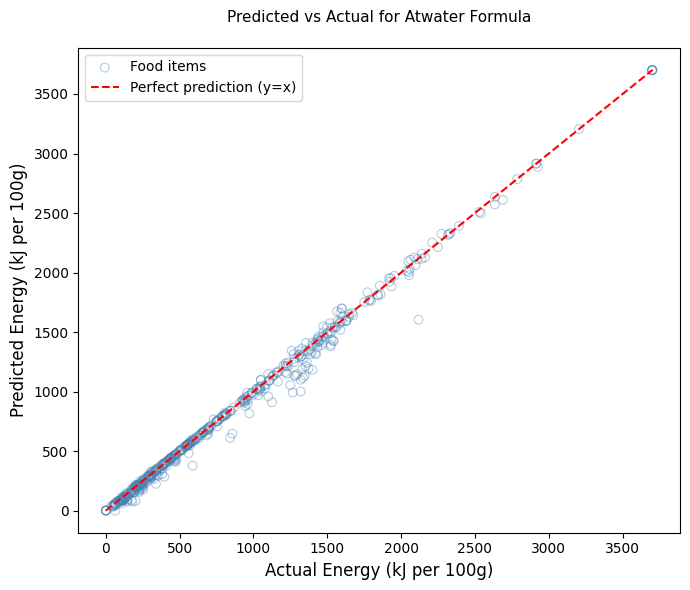

In [11]:
import pandas as pd
import numpy as np
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# â”€â”€ Atwater energy conversion factors (kJ per gram) â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
ATWATER = {
    'Protein (g)':                                        17,
    'Fat, total (g)':                                     37,
    'Available carbohydrate, without sugar alcohols (g)': 17,
    'Alcohol (g)':                                        29,
}

def compute_atwater(df):
    """
    Compute Atwater predicted energy (kJ) for each food in df.
    Missing macronutrient values are treated as zero (not measured â‰ˆ absent).
    """
    energy = pd.Series(0.0, index=df.index)
    for col, factor in ATWATER.items():
        if col in df.columns:
            energy += df[col].fillna(0) * factor
        else:
            print(f"Warning: '{col}' not found in DataFrame â€” skipping.")
    return energy


# â”€â”€ Apply to test set â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
# X_test and y_test are assumed to be already defined from the preprocessing pipeline.
# Identifier columns were separated before splitting, so X_test contains only features.

y_pred_atwater = compute_atwater(X_test)

# â”€â”€ Evaluation metrics â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
r2_atwater   = r2_score(y_test, y_pred_atwater)
rmse_atwater = np.sqrt(mean_squared_error(y_test, y_pred_atwater))
mae_atwater  = mean_absolute_error(y_test, y_pred_atwater)

print("â”€â”€ Atwater Baseline â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€")
print(f"RÂ²   : {r2_atwater:.4f}")
print(f"RMSE : {rmse_atwater:.2f} kJ")
print(f"MAE  : {mae_atwater:.2f} kJ")

# â”€â”€ Predicted vs Actual scatter plot â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_test, y_pred_atwater, alpha=0.4, edgecolors='steelblue',
           facecolors='none', linewidths=0.8, s=40, label='Food items')

# Perfect prediction line
lims = [min(y_test.min(), y_pred_atwater.min()),
        max(y_test.max(), y_pred_atwater.max())]
ax.plot(lims, lims, 'r--', linewidth=1.5, label='Perfect prediction (y=x)')

ax.set_xlabel('Actual Energy (kJ per 100g)', fontsize=12)
ax.set_ylabel('Predicted Energy (kJ per 100g)', fontsize=12)
ax.set_title('Predicted vs Actual for Atwater Formula\n', fontsize=11)
ax.legend()
plt.tight_layout()
plt.savefig('atwater_predicted_vs_actual.png', dpi=150)
plt.show()

C:\Users\mingx\AppData\Local\Temp\ipykernel_22600\4036826847.py:30: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


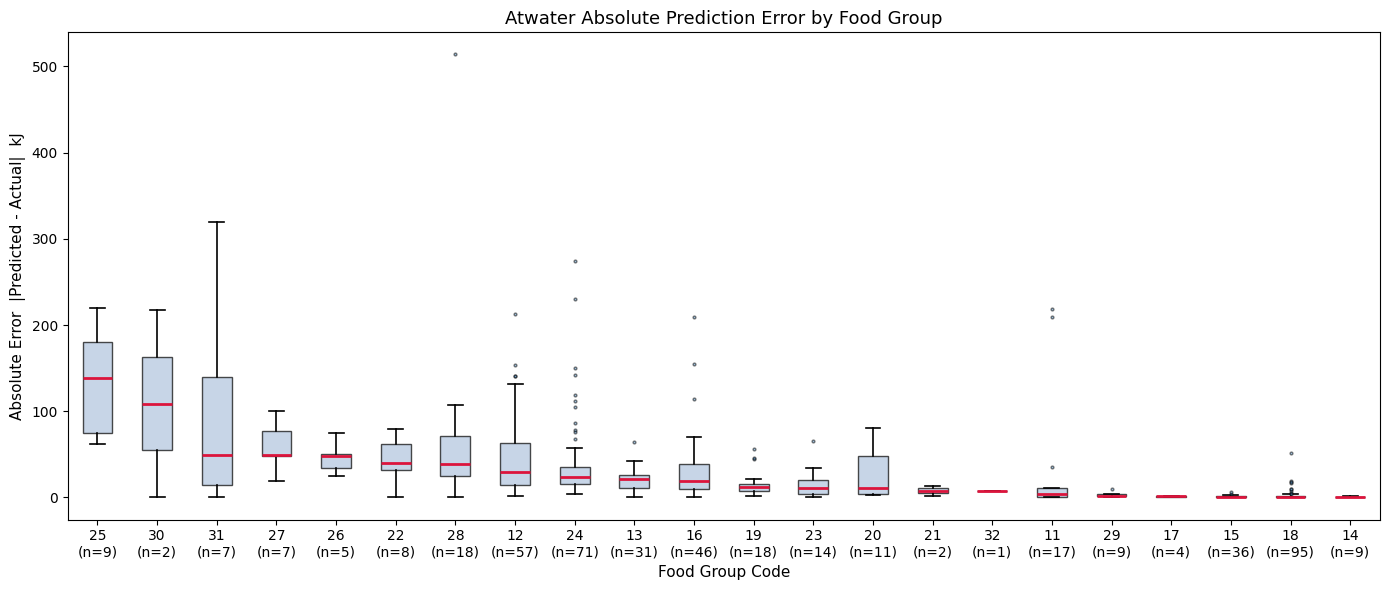

In [12]:
# â”€â”€ Rejoin Classification to test predictions â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
residuals_df = pd.DataFrame({
    'Actual':         y_test.values,
    'Predicted':      y_pred_atwater.values,
    'Abs Error':      np.abs(y_pred_atwater.values - y_test.values),
    'Classification': AFCD.loc[y_test.index, 'Classification'].values,
})

# â”€â”€ Group by first 2 digits of classification â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
residuals_df['FoodGroup'] = residuals_df['Classification'].astype(str).str[:2]

# Order groups by median absolute error descending
group_order = (
    residuals_df.groupby('FoodGroup')['Abs Error']
    .median()
    .sort_values(ascending=False)
    .index.tolist()
)

grouped_errors = [
    residuals_df.loc[residuals_df['FoodGroup'] == g, 'Abs Error'].values
    for g in group_order
]

counts = residuals_df['FoodGroup'].value_counts()

# â”€â”€ Box plot â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
fig, ax = plt.subplots(figsize=(14, 6))

ax.boxplot(
    grouped_errors,
    labels=[f"{g}\n(n={counts[g]})" for g in group_order],
    patch_artist=True,
    medianprops=dict(color='crimson', linewidth=2),
    flierprops=dict(marker='.', markersize=4, alpha=0.5, markerfacecolor='steelblue'),
    boxprops=dict(facecolor='lightsteelblue', alpha=0.7),
    whiskerprops=dict(linewidth=1.2),
    capprops=dict(linewidth=1.2),
)

ax.set_title('Atwater Absolute Prediction Error by Food Group', fontsize=13)
ax.set_xlabel('Food Group Code', fontsize=11)
ax.set_ylabel('Absolute Error  |Predicted - Actual|  kJ', fontsize=11)
plt.tight_layout()
plt.savefig('atwater_abs_error_by_foodgroup.png', dpi=150, bbox_inches='tight')
plt.show()

In [13]:
summary = (
    residuals_df.groupby('FoodGroup')['Abs Error']
    .agg(Count='count', Median_MAE='median', Mean_MAE='mean')
    .sort_values('Median_MAE', ascending=False)
    .reset_index()
)
summary.index += 1
print(f"{'#':<4} {'Group':>6}  {'Count':>6}  {'Median AE':>10}  {'Mean AE':>10}")
print("-" * 44)
for i, row in summary.iterrows():
    print(f"{i:<4} {row['FoodGroup']:>6}  {int(row['Count']):>6}  {row['Median_MAE']:>10.1f}  {row['Mean_MAE']:>10.1f}")

#     Group   Count   Median AE     Mean AE
--------------------------------------------
1        25       9       138.3       132.7
2        30       2       108.7       108.7
3        31       7        49.6        96.6
4        27       7        49.2        59.8
5        26       5        48.5        46.4
6        22       8        39.4        42.2
7        28      18        39.2        69.4
8        12      57        29.1        45.9
9        24      71        23.8        38.9
10       13      31        21.6        20.8
11       16      46        18.7        32.4
12       19      18        11.7        16.5
13       23      14        10.5        15.8
14       20      11        10.4        26.1
15       21       2         7.8         7.8
16       32       1         7.1         7.1
17       11      17         3.5        30.2
18       29       9         2.0         2.9
19       17       4         1.1         1.2
20       15      36         0.8         1.0
21       18      95         0.5

In [14]:
THRESHOLD = 0.95

corr_matrix = X_train.corr(method='pearson')
target_corr = X_train.corrwith(y_train).abs()

upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

to_drop = set()
drop_log = []
for col in upper.columns:
    high = upper[col][upper[col].abs() >= THRESHOLD]
    for idx, val in high.items():
        if target_corr[col] <= target_corr[idx]:
            kept, dropped = idx, col
        else:
            kept, dropped = col, idx
        to_drop.add(dropped)
        drop_log.append({
            'Kept': kept,
            'Dropped': dropped,
            'Pair r': round(val, 4),
            'Kept |r_target|': round(target_corr[kept], 4),
            'Dropped |r_target|': round(target_corr[dropped], 4),
        })

drop_log_df = pd.DataFrame(drop_log).sort_values('Pair r', ascending=False).reset_index(drop=True)
drop_log_df.index += 1

print(f"{'#':<4} {'Kept':<50} {'Dropped':<50} {'Pair r':>6}  {'Kept |r_y|':>10}  {'Drop |r_y|':>10}")
print("-" * 140)
for i, row in drop_log_df.iterrows():
    print(f"{i:<4} {row['Kept']:<50} {row['Dropped']:<50} {row['Pair r']:>6.4f}  {row['Kept |r_target|']:>10.4f}  {row['Dropped |r_target|']:>10.4f}")

high_corr_cols = list(to_drop)
X_train = X_train.drop(columns=high_corr_cols)
X_test  = X_test.drop(columns=high_corr_cols)

print(f"\nThreshold         : {THRESHOLD}")
print(f"Columns dropped   : {len(high_corr_cols)}")
print(f"Columns remaining : {X_train.shape[1]}")

#    Kept                                               Dropped                                            Pair r  Kept |r_y|  Drop |r_y|
--------------------------------------------------------------------------------------------------------------------------------------------
1    Tryptophan (mg)                                    Niacin derived from tryptophan (mg)                1.0000      0.1640      0.1639
2    Available carbohydrate, without sugar alcohols (g) Available carbohydrate, with sugar alcohols (g)    0.9998      0.3374      0.3362
3    Vitamin E (mg)                                     Alpha tocopherol (mg)                              0.9962      0.4550      0.4349
4    C18:1 (g)                                          Total monounsaturated fatty acids, equated (g)     0.9948      0.7658      0.7547
5    Nitrogen (g)                                       Protein (g)                                        0.9928      0.1460      0.1360
6    Beta-carotene equivalents 

Fitting 5 folds for each of 54 candidates, totalling 270 fits
Best hyperparameters: {'max_depth': 20, 'max_features': 0.33, 'min_samples_leaf': 1, 'n_estimators': 500}
Best CV RMSE: 85.88 kJ


C:\Users\mingx\AppData\Local\Temp\ipykernel_22600\4252082220.py:58: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


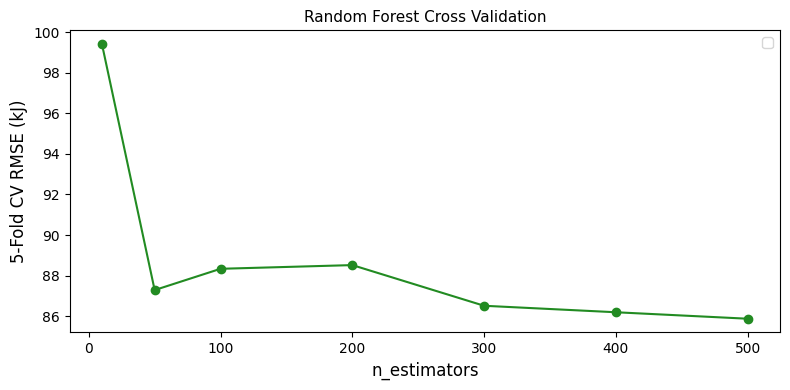

â”€â”€ Random Forest â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
RÂ²   : 0.9906
RMSE : 68.83 kJ
MAE  : 40.16 kJ


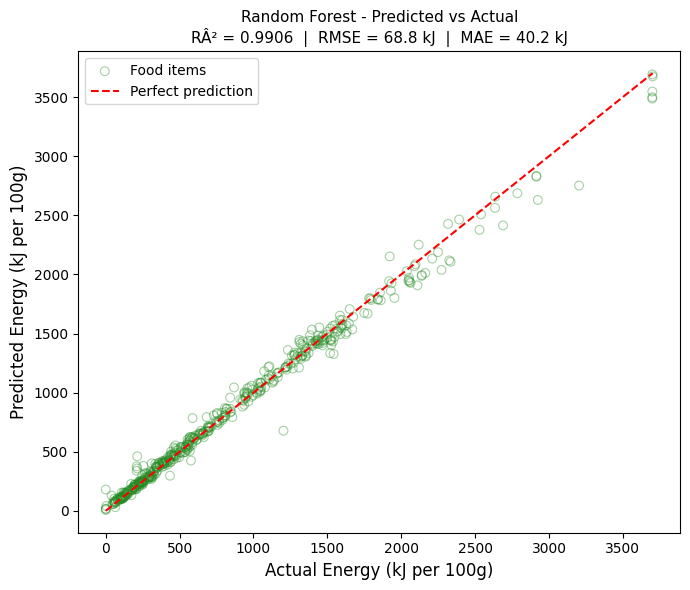


Top 15 most important features (Random Forest MDI):
                                           Feature  Importance
                              Moisture (water) (g)    0.341563
                                    Fat, total (g)    0.226137
          Total saturated fatty acids, equated (g)    0.084777
                                           C16 (g)    0.057022
                                         C18:1 (g)    0.056773
    Total polyunsaturated fatty acids, equated (g)    0.042385
Available carbohydrate, without sugar alcohols (g)    0.040491
                                Potassium (K) (mg)    0.013163
                                           Ash (g)    0.012374
                                       C18:3w3 (g)    0.011917
                               Phosphorus (P) (mg)    0.011229
                                        Starch (g)    0.010766
                                      Nitrogen (g)    0.009784
                               Magnesium (Mg) (mg)    0.009135
  

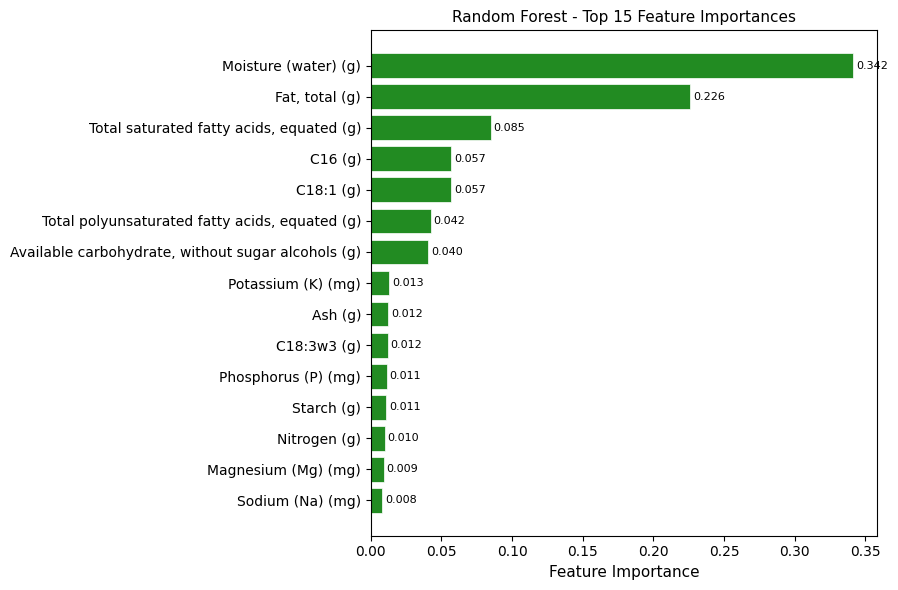

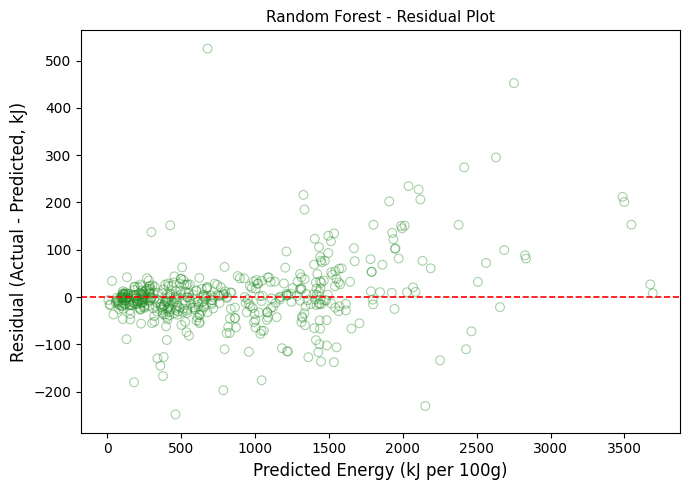

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score, KFold, GridSearchCV
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# â”€â”€ Hyperparameter tuning via 5-fold cross-validation â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
# A targeted grid is used; expand if computation allows.
param_grid = {
    'n_estimators':     [100, 300, 500],
    'max_features':     ['sqrt', 0.33],   # sqrt(65) â‰ˆ 8; 0.33*65 â‰ˆ 22
    'max_depth':        [None, 20, 40],   # None = fully grown trees
    'min_samples_leaf': [1, 2, 4],
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)

rf_base = RandomForestRegressor(random_state=42, n_jobs=-1)

grid_search = GridSearchCV(
    estimator  = rf_base,
    param_grid = param_grid,
    cv         = kf,
    scoring    = 'neg_root_mean_squared_error',
    n_jobs     = -1,
    verbose    = 1
)
grid_search.fit(X_train, y_train)

best_params = grid_search.best_params_
print("Best hyperparameters:", best_params)
print(f"Best CV RMSE: {-grid_search.best_score_:.2f} kJ")

# â”€â”€ Plot: CV RMSE vs n_estimators (fixing other params at best values) â”€â”€â”€â”€â”€â”€â”€â”€
# Re-run a focused sweep over n_estimators to show convergence behaviour.
n_est_range = [10, 50, 100, 200, 300, 400, 500]
cv_rmse_n   = []

for n in n_est_range:
    rf = RandomForestRegressor(
        n_estimators    = n,
        max_features    = best_params['max_features'],
        max_depth       = best_params['max_depth'],
        min_samples_leaf= best_params['min_samples_leaf'],
        random_state    = 42,
        n_jobs          = -1
    )
    scores = cross_val_score(rf, X_train, y_train,
                             cv=kf, scoring='neg_root_mean_squared_error')
    cv_rmse_n.append(-scores.mean())

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(n_est_range, cv_rmse_n, marker='o', color='forestgreen', linewidth=1.5)
ax.set_xlabel('n_estimators', fontsize=12)
ax.set_ylabel('5-Fold CV RMSE (kJ)', fontsize=12)
ax.set_title('Random Forest Cross Validation', fontsize=11)
ax.legend()
plt.tight_layout()
plt.savefig('rf_cv_n_estimators.png', dpi=150)
plt.show()

# â”€â”€ Train final model with best hyperparameters â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
rf_final = RandomForestRegressor(**best_params, random_state=42, n_jobs=-1)
rf_final.fit(X_train, y_train)

# â”€â”€ Evaluate on test set â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
y_pred_rf = rf_final.predict(X_test)

r2_rf   = r2_score(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
mae_rf  = mean_absolute_error(y_test, y_pred_rf)

print("â”€â”€ Random Forest â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€")
print(f"RÂ²   : {r2_rf:.4f}")
print(f"RMSE : {rmse_rf:.2f} kJ")
print(f"MAE  : {mae_rf:.2f} kJ")

# â”€â”€ Predicted vs Actual scatter plot â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_test, y_pred_rf, alpha=0.4, edgecolors='forestgreen',
           facecolors='none', linewidths=0.8, s=40, label='Food items')

lims = [min(y_test.min(), y_pred_rf.min()),
        max(y_test.max(), y_pred_rf.max())]
ax.plot(lims, lims, 'r--', linewidth=1.5, label='Perfect prediction')

ax.set_xlabel('Actual Energy (kJ per 100g)', fontsize=12)
ax.set_ylabel('Predicted Energy (kJ per 100g)', fontsize=12)
ax.set_title(f'Random Forest - Predicted vs Actual\n'
             f'RÂ² = {r2_rf:.4f}  |  RMSE = {rmse_rf:.1f} kJ  |  MAE = {mae_rf:.1f} kJ',
             fontsize=11)
ax.legend()
plt.tight_layout()
plt.savefig('rf_predicted_vs_actual.png', dpi=150)
plt.show()

# â”€â”€ Feature importance (MDI â€” Mean Decrease in Impurity) â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
importances = rf_final.feature_importances_
feature_names = X_train.columns.tolist()

importance_df = pd.DataFrame({
    'Feature':    feature_names,
    'Importance': importances
}).sort_values('Importance', ascending=False).reset_index(drop=True)

print("\nTop 15 most important features (Random Forest MDI):")
print(importance_df.head(15).to_string(index=False))

# â”€â”€ Bar chart: Top 15 feature importances â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
top15 = importance_df.head(15)

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(top15['Feature'][::-1], top15['Importance'][::-1],
               color='forestgreen', edgecolor='white', linewidth=0.5)
ax.set_xlabel('Feature Importance', fontsize=11)
ax.set_title('Random Forest - Top 15 Feature Importances', fontsize=11)

# Annotate bars with percentage values
for bar, val in zip(bars, top15['Importance'][::-1]):
    ax.text(bar.get_width() + 0.002, bar.get_y() + bar.get_height() / 2,
            f'{val:.3f}', va='center', fontsize=8)

plt.tight_layout()
plt.savefig('rf_feature_importance.png', dpi=150)
plt.show()

# â”€â”€ Residual plot â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
residuals = y_test - y_pred_rf

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(y_pred_rf, residuals, alpha=0.4, edgecolors='forestgreen',
           facecolors='none', linewidths=0.8, s=40)
ax.axhline(0, color='red', linestyle='--', linewidth=1.2)
ax.set_xlabel('Predicted Energy (kJ per 100g)', fontsize=12)
ax.set_ylabel('Residual (Actual - Predicted, kJ)', fontsize=12)
ax.set_title('Random Forest - Residual Plot', fontsize=11)
plt.tight_layout()
plt.savefig('rf_residuals.png', dpi=150)
plt.show()

# â”€â”€ Export importance table to CSV â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
importance_df.to_csv('rf_feature_importances.csv', index=False)

C:\Users\mingx\AppData\Local\Temp\ipykernel_22600\1231403215.py:25: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


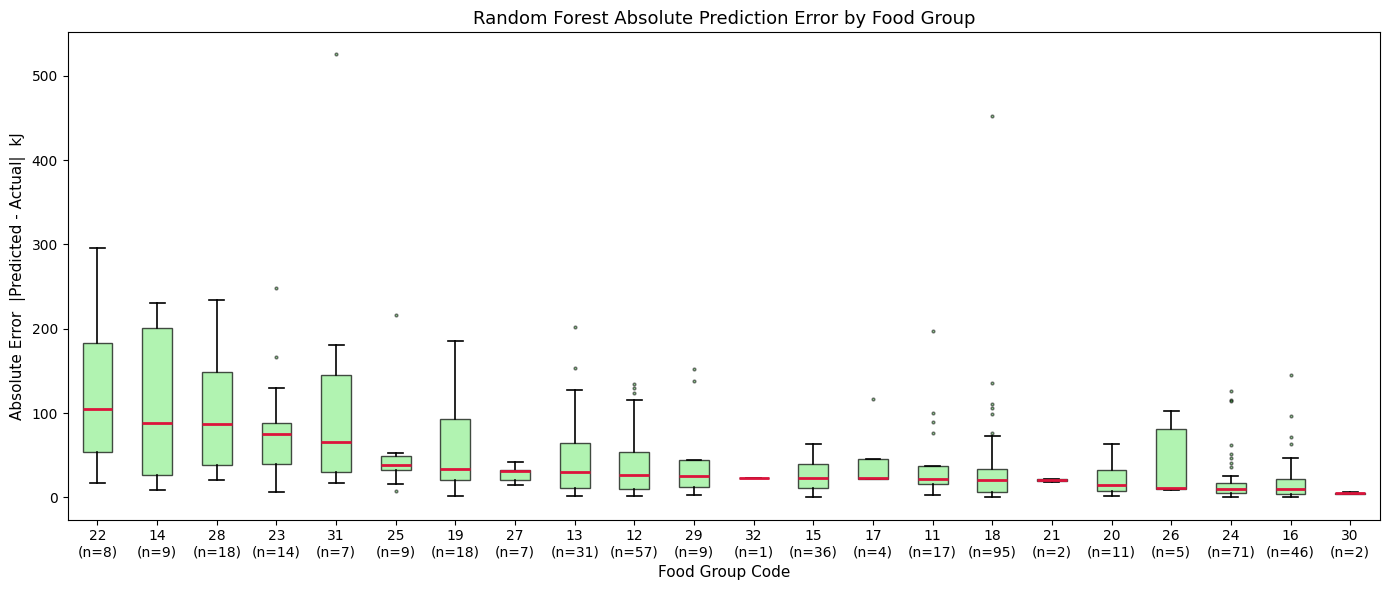

#     Group   Count   Median AE     Mean AE
--------------------------------------------
1        22       8       104.9       130.3
2        14       9        88.3       113.6
3        28      18        86.6       102.6
4        23      14        74.9        82.2
5        31       7        65.7       136.8
6        25       9        38.1        54.1
7        19      18        34.0        59.3
8        27       7        30.9        27.4
9        13      31        29.7        48.8
10       12      57        26.8        37.7
11       29       9        24.9        49.2
12       32       1        23.5        23.5
13       15      36        23.2        25.4
14       17       4        22.5        45.8
15       11      17        21.6        40.7
16       18      95        20.8        29.8
17       21       2        20.5        20.5
18       20      11        14.9        23.7
19       26       5        11.1        43.0
20       24      71         9.8        17.1
21       16      46         9.8

In [16]:
rf_residuals_df = pd.DataFrame({
    'Actual':         y_test.values,
    'Predicted':      y_pred_rf,
    'Abs Error':      np.abs(y_pred_rf - y_test.values),
    'Classification': AFCD.loc[y_test.index, 'Classification'].values,
})

rf_residuals_df['FoodGroup'] = rf_residuals_df['Classification'].astype(str).str[:2]

group_order_rf = (
    rf_residuals_df.groupby('FoodGroup')['Abs Error']
    .median()
    .sort_values(ascending=False)
    .index.tolist()
)

grouped_errors_rf = [
    rf_residuals_df.loc[rf_residuals_df['FoodGroup'] == g, 'Abs Error'].values
    for g in group_order_rf
]

counts_rf = rf_residuals_df['FoodGroup'].value_counts()

fig, ax = plt.subplots(figsize=(14, 6))
ax.boxplot(
    grouped_errors_rf,
    labels=[f"{g}\n(n={counts_rf[g]})" for g in group_order_rf],
    patch_artist=True,
    medianprops=dict(color='crimson', linewidth=2),
    flierprops=dict(marker='.', markersize=4, alpha=0.5, markerfacecolor='forestgreen'),
    boxprops=dict(facecolor='lightgreen', alpha=0.7),
    whiskerprops=dict(linewidth=1.2),
    capprops=dict(linewidth=1.2),
)
ax.set_title('Random Forest Absolute Prediction Error by Food Group', fontsize=13)
ax.set_xlabel('Food Group Code', fontsize=11)
ax.set_ylabel('Absolute Error  |Predicted - Actual|  kJ', fontsize=11)
plt.tight_layout()
plt.savefig('rf_abs_error_by_foodgroup.png', dpi=150, bbox_inches='tight')
plt.show()

summary_rf = (
    rf_residuals_df.groupby('FoodGroup')['Abs Error']
    .agg(Count='count', Median_MAE='median', Mean_MAE='mean')
    .sort_values('Median_MAE', ascending=False)
    .reset_index()
)
summary_rf.index += 1
print(f"{'#':<4} {'Group':>6}  {'Count':>6}  {'Median AE':>10}  {'Mean AE':>10}")
print("-" * 44)
for i, row in summary_rf.iterrows():
    print(f"{i:<4} {row['FoodGroup']:>6}  {int(row['Count']):>6}  {row['Median_MAE']:>10.1f}  {row['Mean_MAE']:>10.1f}")


Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best params (random search): {'subsample': 0.6, 'reg_lambda': 0.5, 'reg_alpha': 0.01, 'n_estimators': 1000, 'max_depth': 4, 'learning_rate': 0.01, 'colsample_bytree': 0.8}
Best CV RMSE (random search): 54.66 kJ
Fitting 5 folds for each of 27 candidates, totalling 135 fits
Best params (grid search): {'colsample_bytree': 0.8, 'learning_rate': 0.02, 'max_depth': 4, 'n_estimators': 1100, 'reg_alpha': 0.01, 'reg_lambda': 0.5, 'subsample': 0.6}
Best CV RMSE (grid search): 53.92 kJ


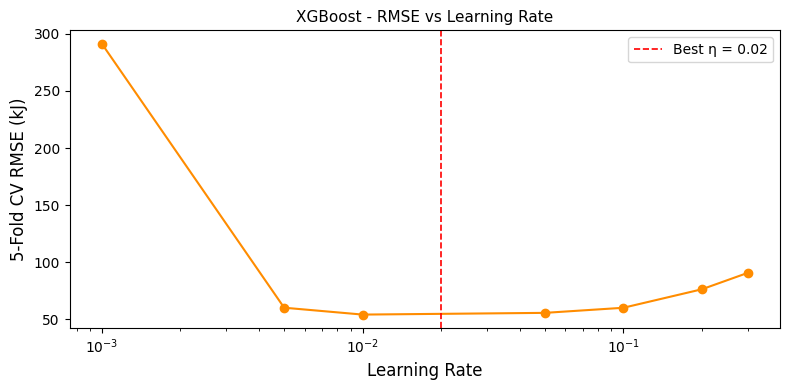

── XGBoost ───────────────────────────────────────
R²   : 0.9959
RMSE : 45.55 kJ
MAE  : 28.16 kJ


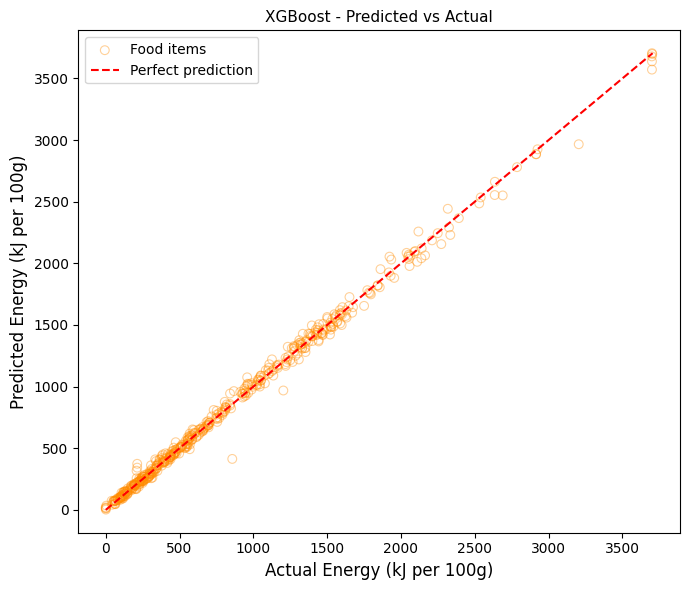

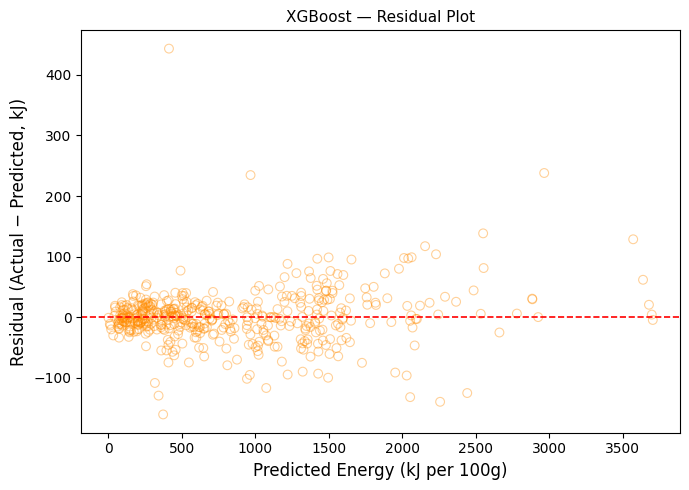


Top 15 most important features (XGBoost gain):
                                           Feature         Gain  Gain_normalised
                                    Fat, total (g) 3.557510e+06         0.324972
                              Moisture (water) (g) 3.268782e+06         0.298597
          Total saturated fatty acids, equated (g) 8.116742e+05         0.074145
Available carbohydrate, without sugar alcohols (g) 7.498412e+05         0.068497
                                         C18:1 (g) 4.110499e+05         0.037549
                                Potassium (K) (mg) 3.020777e+05         0.027594
                                 Calcium (Ca) (mg) 2.365662e+05         0.021610
                                  Sodium (Na) (mg) 2.072192e+05         0.018929
                                           Ash (g) 1.928154e+05         0.017613
                                           C16 (g) 1.904701e+05         0.017399
                                        Starch (g) 1.840326e+

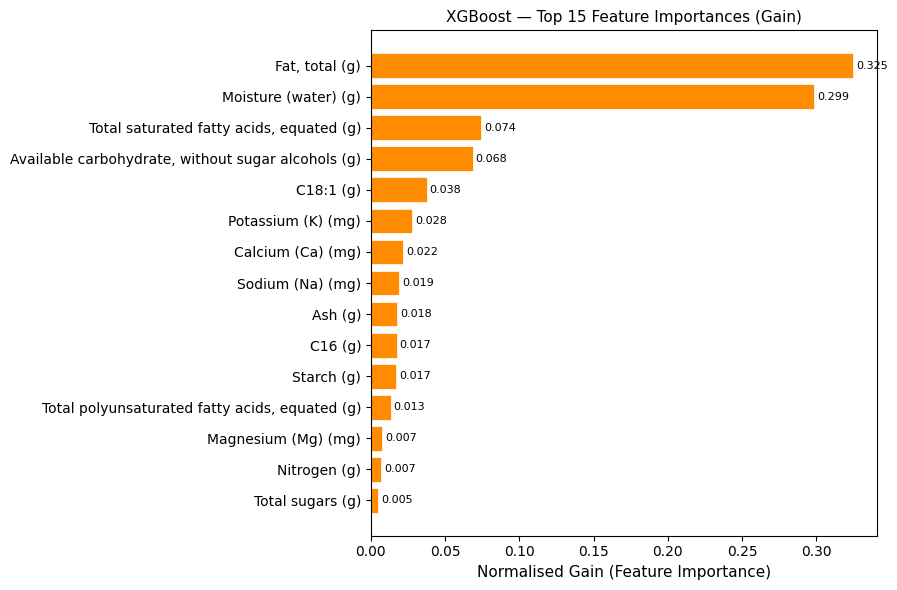

                     Model     R²  RMSE (kJ)  MAE (kJ)
Atwater Formula (Baseline) 0.9936      56.67     28.21
          Ridge Regression    NaN        NaN       NaN
             Random Forest 0.9906      68.83     40.16
                   XGBoost 0.9959      45.55     28.16


In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBRegressor
from sklearn.model_selection import KFold, RandomizedSearchCV, GridSearchCV, cross_val_score
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

kf = KFold(n_splits=5, shuffle=True, random_state=42)

# ── Stage 1: Broad random search ─────────────────────────────────────────────
param_dist = {
    'n_estimators':      [100, 300, 500, 700, 1000],
    'learning_rate':     [0.01, 0.05, 0.1, 0.2, 0.3],
    'max_depth':         [3, 4, 5, 6, 7],
    'subsample':         [0.6, 0.7, 0.8, 0.9, 1.0],
    'colsample_bytree':  [0.5, 0.6, 0.7, 0.8, 1.0],
    'reg_alpha':         [0, 0.01, 0.1, 1.0],
    'reg_lambda':        [0.5, 1.0, 2.0, 5.0],
}

xgb_base = XGBRegressor(
    objective   = 'reg:squarederror',
    random_state= 42,
    n_jobs      = -1,
    verbosity   = 0
)

random_search = RandomizedSearchCV(
    estimator          = xgb_base,
    param_distributions= param_dist,
    n_iter             = 50,          # 50 random combinations
    cv                 = kf,
    scoring            = 'neg_root_mean_squared_error',
    random_state       = 42,
    n_jobs             = -1,
    verbose            = 1
)
random_search.fit(X_train, y_train)

print("Best params (random search):", random_search.best_params_)
print(f"Best CV RMSE (random search): {-random_search.best_score_:.2f} kJ")

# ── Stage 2: Focused grid search around best random search params ─────────────
best_rs = random_search.best_params_

param_grid_focused = {
    'n_estimators':     [best_rs['n_estimators'] - 100,
                         best_rs['n_estimators'],
                         best_rs['n_estimators'] + 100],
    'learning_rate':    [best_rs['learning_rate'] * 0.5,
                         best_rs['learning_rate'],
                         best_rs['learning_rate'] * 2],
    'max_depth':        [max(2, best_rs['max_depth'] - 1),
                         best_rs['max_depth'],
                         best_rs['max_depth'] + 1],
    'subsample':        [best_rs['subsample']],
    'colsample_bytree': [best_rs['colsample_bytree']],
    'reg_alpha':        [best_rs['reg_alpha']],
    'reg_lambda':       [best_rs['reg_lambda']],
}

grid_search = GridSearchCV(
    estimator  = xgb_base,
    param_grid = param_grid_focused,
    cv         = kf,
    scoring    = 'neg_root_mean_squared_error',
    n_jobs     = -1,
    verbose    = 1
)
grid_search.fit(X_train, y_train)

best_params = grid_search.best_params_
print("Best params (grid search):", best_params)
print(f"Best CV RMSE (grid search): {-grid_search.best_score_:.2f} kJ")

# ── Plot: CV RMSE vs learning rate (fixing other params at best values) ───────
lr_range  = [0.001, 0.005, 0.01, 0.05, 0.1, 0.2, 0.3]
cv_rmse_lr = []

for lr in lr_range:
    xgb = XGBRegressor(
        **{k: v for k, v in best_params.items() if k != 'learning_rate'},
        learning_rate= lr,
        objective    = 'reg:squarederror',
        random_state = 42,
        n_jobs       = -1,
        verbosity    = 0
    )
    scores = cross_val_score(xgb, X_train, y_train,
                             cv=kf, scoring='neg_root_mean_squared_error')
    cv_rmse_lr.append(-scores.mean())

fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogx(lr_range, cv_rmse_lr, marker='o', color='darkorange', linewidth=1.5)
ax.axvline(best_params['learning_rate'], color='red', linestyle='--',
           linewidth=1.2, label=f"Best η = {best_params['learning_rate']}")
ax.set_xlabel('Learning Rate', fontsize=12)
ax.set_ylabel('5-Fold CV RMSE (kJ)', fontsize=12)
ax.set_title('XGBoost - RMSE vs Learning Rate', fontsize=11)
ax.legend()
plt.tight_layout()
plt.savefig('xgb_cv_learning_rate.png', dpi=150)
plt.show()

# ── Train final model with best hyperparameters ───────────────────────────────
xgb_final = XGBRegressor(
    **best_params,
    objective   = 'reg:squarederror',
    random_state= 42,
    n_jobs      = -1,
    verbosity   = 0
)
xgb_final.fit(X_train, y_train)

# ── Evaluate on test set ──────────────────────────────────────────────────────
y_pred_xgb = xgb_final.predict(X_test)

r2_xgb   = r2_score(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
mae_xgb  = mean_absolute_error(y_test, y_pred_xgb)

print("── XGBoost ───────────────────────────────────────")
print(f"R²   : {r2_xgb:.4f}")
print(f"RMSE : {rmse_xgb:.2f} kJ")
print(f"MAE  : {mae_xgb:.2f} kJ")

# ── Predicted vs Actual scatter plot ─────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_test, y_pred_xgb, alpha=0.4, edgecolors='darkorange',
           facecolors='none', linewidths=0.8, s=40, label='Food items')

lims = [min(y_test.min(), y_pred_xgb.min()),
        max(y_test.max(), y_pred_xgb.max())]
ax.plot(lims, lims, 'r--', linewidth=1.5, label='Perfect prediction')

ax.set_xlabel('Actual Energy (kJ per 100g)', fontsize=12)
ax.set_ylabel('Predicted Energy (kJ per 100g)', fontsize=12)
ax.set_title(f'XGBoost - Predicted vs Actual',
             fontsize=11)
ax.legend()
plt.tight_layout()
plt.savefig('xgb_predicted_vs_actual.png', dpi=150)
plt.show()

# ── Residual plot ─────────────────────────────────────────────────────────────
residuals_xgb = y_test - y_pred_xgb

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(y_pred_xgb, residuals_xgb, alpha=0.4, edgecolors='darkorange',
           facecolors='none', linewidths=0.8, s=40)
ax.axhline(0, color='red', linestyle='--', linewidth=1.2)
ax.set_xlabel('Predicted Energy (kJ per 100g)', fontsize=12)
ax.set_ylabel('Residual (Actual − Predicted, kJ)', fontsize=12)
ax.set_title('XGBoost — Residual Plot', fontsize=11)
plt.tight_layout()
plt.savefig('xgb_residuals.png', dpi=150)
plt.show()

# ── Feature importance (gain-based) ──────────────────────────────────────────
# XGBoost provides several importance types; 'gain' is most comparable to RF MDI.
importance_gain = xgb_final.get_booster().get_score(importance_type='gain')

importance_df_xgb = pd.DataFrame({
    'Feature':    list(importance_gain.keys()),
    'Gain':       list(importance_gain.values())
}).sort_values('Gain', ascending=False).reset_index(drop=True)

# Normalise so scores sum to 1 for comparability with RF importances
importance_df_xgb['Gain_normalised'] = (
    importance_df_xgb['Gain'] / importance_df_xgb['Gain'].sum()
)

print("\nTop 15 most important features (XGBoost gain):")
print(importance_df_xgb.head(15).to_string(index=False))

# ── Bar chart: Top 15 feature importances ────────────────────────────────────
top15_xgb = importance_df_xgb.head(15)

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(top15_xgb['Feature'][::-1], top15_xgb['Gain_normalised'][::-1],
               color='darkorange', edgecolor='white', linewidth=0.5)
ax.set_xlabel('Normalised Gain (Feature Importance)', fontsize=11)
ax.set_title('XGBoost — Top 15 Feature Importances (Gain)', fontsize=11)

for bar, val in zip(bars, top15_xgb['Gain_normalised'][::-1]):
    ax.text(bar.get_width() + 0.002, bar.get_y() + bar.get_height() / 2,
            f'{val:.3f}', va='center', fontsize=8)

plt.tight_layout()
plt.savefig('xgb_feature_importance.png', dpi=150)
plt.show()

# ── Export results ────────────────────────────────────────────────────────────
importance_df_xgb.to_csv('xgb_feature_importances.csv', index=False)

# ── Full model comparison table ───────────────────────────────────────────────
results_all = pd.DataFrame({
    'Model':     ['Atwater Formula (Baseline)', 'Ridge Regression',
                  'Random Forest',              'XGBoost'],
    'R²':        [0.9936,       None,    0.9906,    round(r2_xgb, 4)],
    'RMSE (kJ)': [56.67,        None,    68.83,     round(rmse_xgb, 2)],
    'MAE (kJ)':  [28.21,        None,    40.16,     round(mae_xgb, 2)]
})
# Fill in Ridge results once available
print(results_all.to_string(index=False))
results_all.to_csv('all_models_results.csv', index=False)

C:\Users\mingx\AppData\Local\Temp\ipykernel_22600\195931667.py:15: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


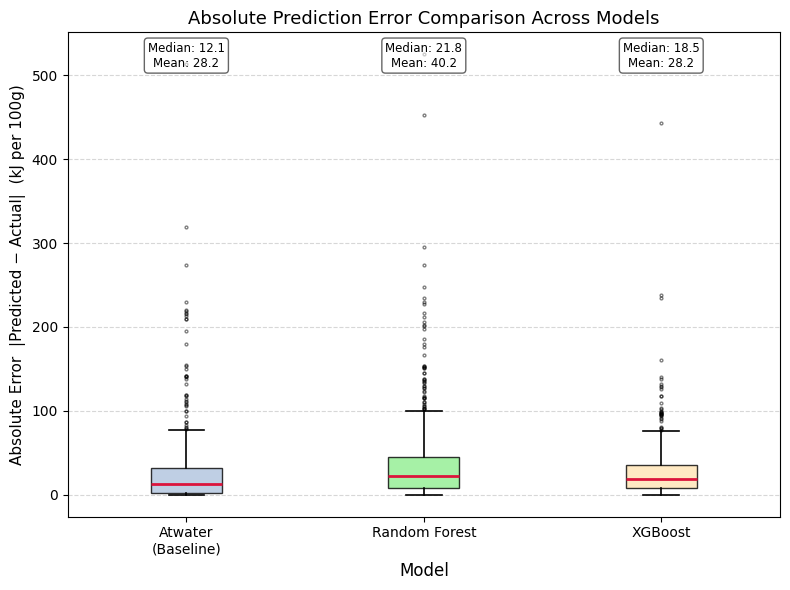

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# ── Box plot: Absolute Error comparison across all 3 models ──────────────────
abs_err_atwater = np.abs(y_pred_atwater.values - y_test.values)
abs_err_rf      = np.abs(y_pred_rf - y_test.values)
abs_err_xgb     = np.abs(y_pred_xgb - y_test.values)

model_errors = [abs_err_atwater, abs_err_rf, abs_err_xgb]
model_labels = ['Atwater\n(Baseline)', 'Random Forest', 'XGBoost']
colors       = ['lightsteelblue', 'lightgreen', 'moccasin']

fig, ax = plt.subplots(figsize=(8, 6))

bp = ax.boxplot(
    model_errors,
    labels=model_labels,
    patch_artist=True,
    medianprops=dict(color='crimson', linewidth=2),
    flierprops=dict(marker='.', markersize=4, alpha=0.5),
    whiskerprops=dict(linewidth=1.2),
    capprops=dict(linewidth=1.2),
)

for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.8)

for i, (errors, label) in enumerate(zip(model_errors, model_labels), start=1):
    median = np.median(errors)
    mean   = np.mean(errors)
    ax.text(i, ax.get_ylim()[1] * 0.98,
            f'Median: {median:.1f}\nMean: {mean:.1f}',
            ha='center', va='top', fontsize=8.5,
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.6))

ax.set_title('Absolute Prediction Error Comparison Across Models', fontsize=13)
ax.set_xlabel('Model', fontsize=12)
ax.set_ylabel('Absolute Error  |Predicted − Actual|  (kJ per 100g)', fontsize=11)
ax.yaxis.grid(True, linestyle='--', alpha=0.5)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig('model_abs_error_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


             Model     R²  RMSE (kJ)  MAE (kJ)
Atwater (Baseline) 0.9936    56.6651   28.2124
     Random Forest 0.9906    68.8284   40.1609
           XGBoost 0.9959    45.5525   28.1627


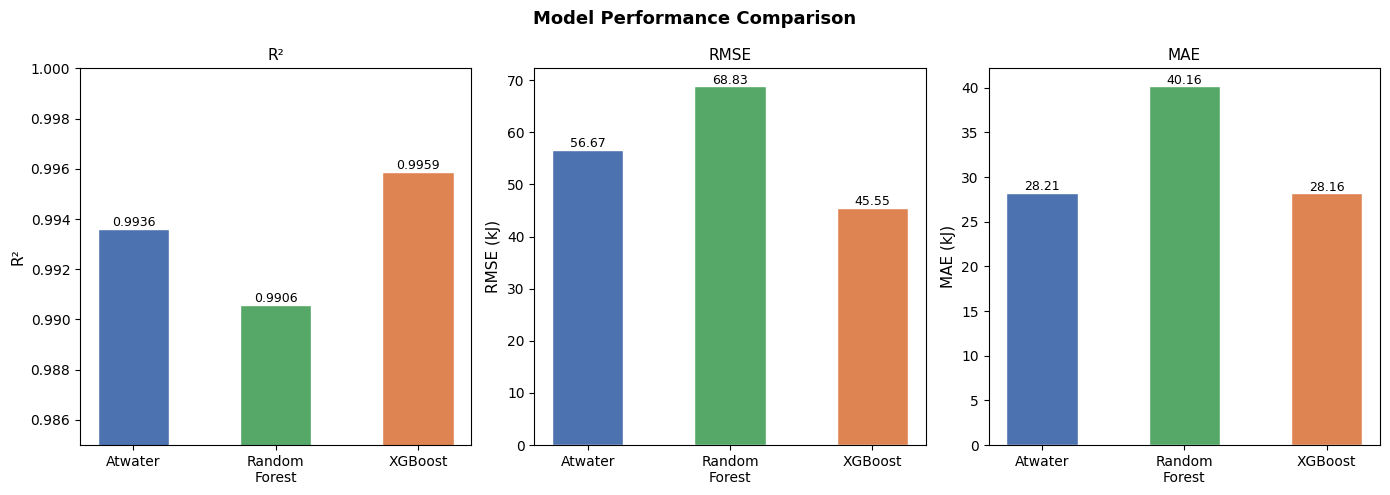

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# ── Summary table ─────────────────────────────────────────────────────────────
# Assumes the following variables are already defined from Sections 3.1–3.3:
#   y_test, y_pred_atwater, y_pred_rf, y_pred_xgb
#   r2_atwater, rmse_atwater, mae_atwater
#   r2_rf,     rmse_rf,     mae_rf
#   r2_xgb,   rmse_xgb,   mae_xgb

results = pd.DataFrame({
    'Model':     ['Atwater (Baseline)', 'Random Forest', 'XGBoost'],
    'R²':        [r2_atwater,           r2_rf,           r2_xgb],
    'RMSE (kJ)': [rmse_atwater,         rmse_rf,         rmse_xgb],
    'MAE (kJ)':  [mae_atwater,          mae_rf,          mae_xgb],
})
print(results.round(4).to_string(index=False))
results.to_csv('model_comparison_results.csv', index=False)

# ── Grouped bar chart: all metrics across all models ─────────────────────────
models  = ['Atwater', 'Random\nForest', 'XGBoost']
r2s     = [r2_atwater,   r2_rf,   r2_xgb]
rmses   = [rmse_atwater, rmse_rf, rmse_xgb]
maes    = [mae_atwater,  mae_rf,  mae_xgb]

x     = np.arange(len(models))
width = 0.25
colours = ['#4C72B0', '#55A868', '#DD8452']   # blue, green, orange

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.suptitle('Model Performance Comparison', fontsize=13, fontweight='bold')

# R²
axes[0].bar(x, r2s, width=0.5, color=colours, edgecolor='white')
axes[0].set_xticks(x)
axes[0].set_xticklabels(models, fontsize=10)
axes[0].set_ylabel('R²', fontsize=11)
axes[0].set_title('R²', fontsize=11)
axes[0].set_ylim([0.985, 1.000])
for i, v in enumerate(r2s):
    axes[0].text(i, v + 0.0001, f'{v:.4f}', ha='center', fontsize=9)

# RMSE
axes[1].bar(x, rmses, width=0.5, color=colours, edgecolor='white')
axes[1].set_xticks(x)
axes[1].set_xticklabels(models, fontsize=10)
axes[1].set_ylabel('RMSE (kJ)', fontsize=11)
axes[1].set_title('RMSE', fontsize=11)
for i, v in enumerate(rmses):
    axes[1].text(i, v + 0.5, f'{v:.2f}', ha='center', fontsize=9)

# MAE
axes[2].bar(x, maes, width=0.5, color=colours, edgecolor='white')
axes[2].set_xticks(x)
axes[2].set_xticklabels(models, fontsize=10)
axes[2].set_ylabel('MAE (kJ)', fontsize=11)
axes[2].set_title('MAE', fontsize=11)
for i, v in enumerate(maes):
    axes[2].text(i, v + 0.3, f'{v:.2f}', ha='center', fontsize=9)

plt.tight_layout()
plt.savefig('model_comparison_bar.png', dpi=150)
plt.show()

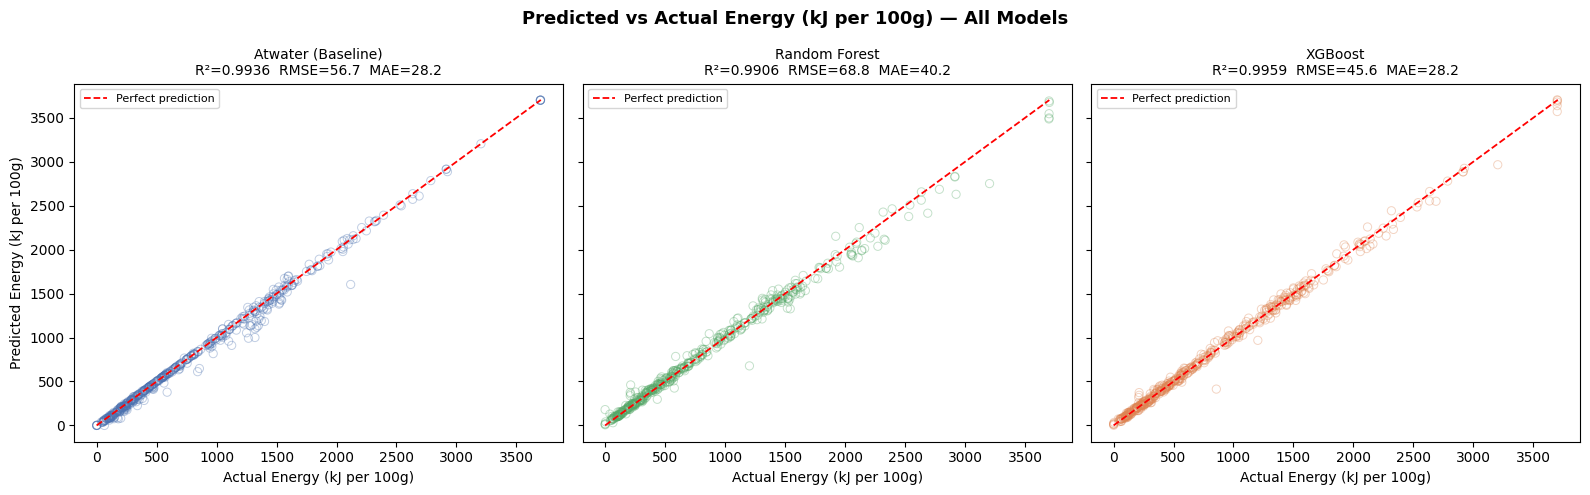

In [20]:
# ── Combined predicted vs actual — 1 row, 3 subplots ─────────────────────────
preds   = [y_pred_atwater, y_pred_rf,      y_pred_xgb]
titles  = ['Atwater (Baseline)', 'Random Forest', 'XGBoost']
colours = ['#4C72B0',            '#55A868',        '#DD8452']
metrics = [
    (r2_atwater, rmse_atwater, mae_atwater),
    (r2_rf,      rmse_rf,      mae_rf),
    (r2_xgb,     rmse_xgb,     mae_xgb),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
fig.suptitle('Predicted vs Actual Energy (kJ per 100g) — All Models',
             fontsize=13, fontweight='bold')

for ax, y_pred, title, colour, (r2, rmse, mae) in zip(
        axes, preds, titles, colours, metrics):

    ax.scatter(y_test, y_pred, alpha=0.35, edgecolors=colour,
               facecolors='none', linewidths=0.7, s=35)

    lims = [min(y_test.min(), y_pred.min()),
            max(y_test.max(), y_pred.max())]
    ax.plot(lims, lims, 'r--', linewidth=1.3, label='Perfect prediction')

    ax.set_title(f'{title}\nR²={r2:.4f}  RMSE={rmse:.1f}  MAE={mae:.1f}',
                 fontsize=10)
    ax.set_xlabel('Actual Energy (kJ per 100g)', fontsize=10)
    ax.legend(fontsize=8)

axes[0].set_ylabel('Predicted Energy (kJ per 100g)', fontsize=10)

plt.tight_layout()
plt.savefig('predicted_vs_actual_all.png', dpi=150)
plt.show()

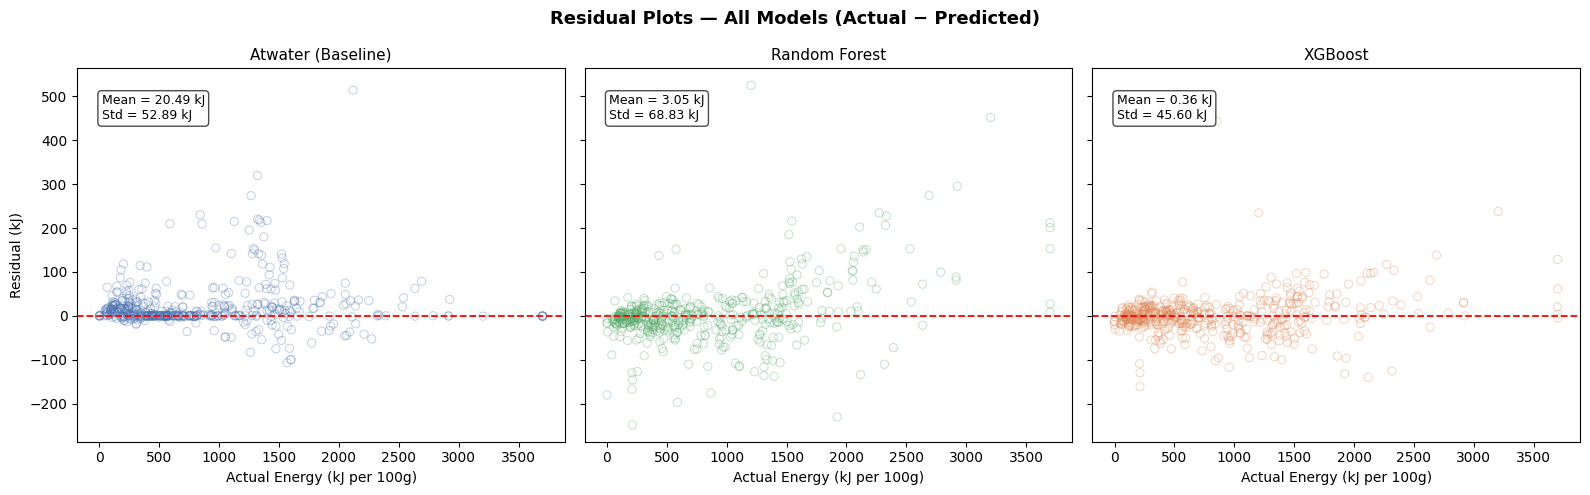

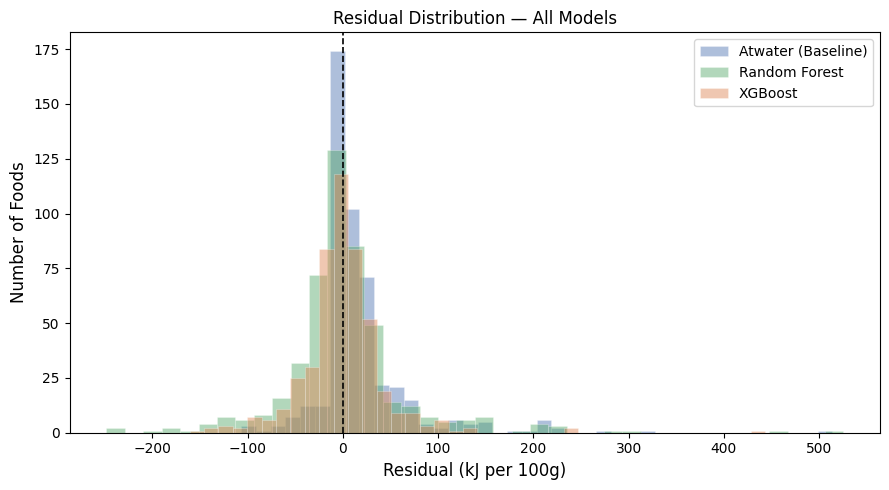

In [21]:
# ── Combined residual plots — 1 row, 3 subplots ───────────────────────────────
residuals = [
    y_test - y_pred_atwater,
    y_test - y_pred_rf,
    y_test - y_pred_xgb,
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
fig.suptitle('Residual Plots — All Models (Actual − Predicted)',
             fontsize=13, fontweight='bold')

for ax, resid, title, colour in zip(axes, residuals, titles, colours):
    ax.scatter(y_test, resid, alpha=0.35, edgecolors=colour,
               facecolors='none', linewidths=0.7, s=35)
    ax.axhline(0, color='red', linestyle='--', linewidth=1.3)

    # Annotate with mean and std of residuals
    mean_r = resid.mean()
    std_r  = resid.std()
    ax.text(0.05, 0.93, f'Mean = {mean_r:.2f} kJ\nStd = {std_r:.2f} kJ',
            transform=ax.transAxes, fontsize=9,
            verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))

    ax.set_title(title, fontsize=11)
    ax.set_xlabel('Actual Energy (kJ per 100g)', fontsize=10)

axes[0].set_ylabel('Residual (kJ)', fontsize=10)

plt.tight_layout()
plt.savefig('residuals_all.png', dpi=150)
plt.show()

# ── Residual distribution: overlaid histogram ─────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 5))

for resid, title, colour in zip(residuals, titles, colours):
    ax.hist(resid, bins=40, alpha=0.45, color=colour,
            label=title, edgecolor='white', linewidth=0.4)

ax.axvline(0, color='black', linestyle='--', linewidth=1.2)
ax.set_xlabel('Residual (kJ per 100g)', fontsize=12)
ax.set_ylabel('Number of Foods', fontsize=12)
ax.set_title('Residual Distribution — All Models', fontsize=12)
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig('residuals_distribution.png', dpi=150)
plt.show()

In [1]:
print(f"All {len(X_train.columns)} features remaining after preprocessing:\n")
for i, col in enumerate(X_train.columns, 1):
    print(f"{i:>3}. {col}")


NameError: name 'X_train' is not defined